# Лабораторная работа: Машина опорных векторов (SVM)

## 0. Подготовка ноутбука

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (6, 4)
plt.rcParams['font.size'] = 12

# фиксируем seed для воспроизводимости случайных экспериментов
np.random.seed(42)

In [2]:
!pip install cvxopt

   ---------------------------------------- 0.0/13.6 MB ? eta -:--:--
    --------------------------------------- 0.3/13.6 MB ? eta -:--:--
   - -------------------------------------- 0.5/13.6 MB 1.6 MB/s eta 0:00:08
   --- ------------------------------------ 1.3/13.6 MB 2.2 MB/s eta 0:00:06
   ----- ---------------------------------- 1.8/13.6 MB 2.5 MB/s eta 0:00:05
   ------- -------------------------------- 2.6/13.6 MB 2.6 MB/s eta 0:00:05
   --------- ------------------------------ 3.1/13.6 MB 2.7 MB/s eta 0:00:04
   ---------- ----------------------------- 3.7/13.6 MB 2.7 MB/s eta 0:00:04
   ------------ --------------------------- 4.2/13.6 MB 2.6 MB/s eta 0:00:04
   ------------- -------------------------- 4.7/13.6 MB 2.7 MB/s eta 0:00:04
   --------------- ------------------------ 5.2/13.6 MB 2.5 MB/s eta 0:00:04
   --------------- ------------------------ 5.2/13.6 MB 2.5 MB/s eta 0:00:04
   ------------------ --------------------- 6.3/13.6 MB 2.6 MB/s eta 0:00:03
   ----------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from cvxopt import matrix, solvers

## <h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 1. Линейное и квадратичное программирование</h2>

### Часть A. Линейное программирование

1. Мебельная мастерская выпускает столы ($x_1$) и стулья ($x_2$). Прибыль: 3 и 2 тыс. руб. за изделие. Цех сборки тратит на стол 2 часа, на стул — 1 час, всего доступно 6 часов; отделка — по 1 часу на любое изделие, всего 4 часа. Составьте задачу LP, переведите максимизацию прибыли в минимизацию и решите её с помощью `solvers.lp`.

In [11]:
# Переменные: x1 - столы, x2 - стулья
# Прибыль: 3*x1 + 2*x2 -> max. Для солвера берем с минусом: c = (-3, -2)
c = matrix(np.array([-3.0, -2.0]), tc='d')
# Ограничения: 2x1 + x2 <= 6, x1 + x2 <= 4, x1 >= 0, x2 >= 0
G = matrix(np.array([[ 2.0,  1.0], 
                     [ 1.0,  1.0], 
                     [-1.0,  0.0], 
                     [ 0.0, -1.0]]), tc='d')
h = matrix(np.array([6.0, 4.0, 0.0, 0.0]), tc='d')

sol_lp = solvers.lp(c, G, h)
print('Оптимальное решение LP (x1, x2):', np.array(sol_lp['x']).ravel())
print('Максимальная прибыль:', -sol_lp['primal objective'])
# Ожидаемый ответ: x = (2, 2), прибыль = 10

     pcost       dcost       gap    pres   dres   k/t
 0: -8.6667e+00 -2.2000e+01  6e+00  0e+00  8e-01  1e+00
 1: -9.5333e+00 -1.1248e+01  7e-01  3e-16  1e-01  1e-01
 2: -9.9770e+00 -1.0052e+01  3e-02  1e-16  5e-03  5e-03
 3: -9.9998e+00 -1.0001e+01  3e-04  2e-16  5e-05  5e-05
 4: -1.0000e+01 -1.0000e+01  3e-06  2e-16  5e-07  5e-07
 5: -1.0000e+01 -1.0000e+01  3e-08  2e-16  5e-09  5e-09
Optimal solution found.
Оптимальное решение LP (x1, x2): [1.99999999 2.        ]
Максимальная прибыль: 9.999999977053385


2. Нарисуйте допустимую область, линии уровня прибыли и решение (по образцу п. 1.3). Проверьте ответ, перебрав все вершины многоугольника: каждую вершину найдите как решение системы двух линейных уравнений и подставьте в прибыль.

<>:10: SyntaxWarning: invalid escape sequence '\('
<>:10: SyntaxWarning: invalid escape sequence '\('
<>:10: SyntaxWarning: invalid escape sequence '\('
<>:10: SyntaxWarning: invalid escape sequence '\('
C:\Users\user\AppData\Local\Temp\ipykernel_5004\2630610975.py:10: SyntaxWarning: invalid escape sequence '\('
  plt.xlabel('\(x_1\)'); plt.ylabel('\(x_2\)')
C:\Users\user\AppData\Local\Temp\ipykernel_5004\2630610975.py:10: SyntaxWarning: invalid escape sequence '\('
  plt.xlabel('\(x_1\)'); plt.ylabel('\(x_2\)')


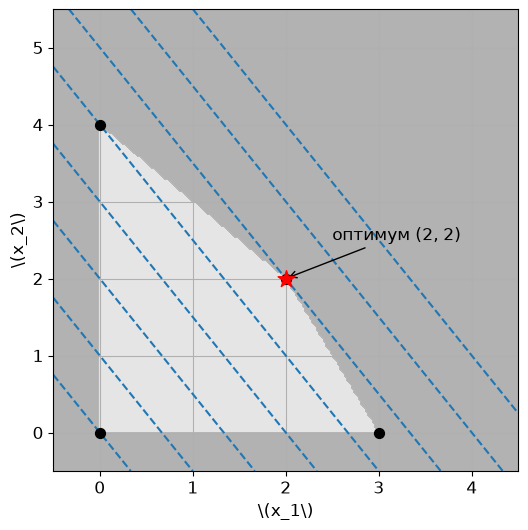

Вершина [0 0]: прибыль = 0
Вершина [3 0]: прибыль = 9
Вершина [2 2]: прибыль = 10
Вершина [0 4]: прибыль = 8


In [12]:
x1 = np.linspace(-0.5, 4.5, 200)
x2 = np.linspace(-0.5, 5.5, 200)
xx1, xx2 = np.meshgrid(x1, x2)
profit = 3*xx1 + 2*xx2
# Булев массив для закраски допустимой области
ok = (2*xx1 + xx2 <= 6) & (xx1 + xx2 <= 4) & (xx1 >= 0) & (xx2 >= 0)

plt.figure(figsize=(6, 6))
plt.grid(True)
plt.xlabel('\(x_1\)'); plt.ylabel('\(x_2\)')
plt.contourf(x1, x2, ok, 1, alpha=0.4, cmap='gray') # Допустимая область серым
plt.contour(x1, x2, profit, levels=np.arange(0, 15, 2), colors='tab:blue', linestyles='--') # Линии уровня

# Вершины многоугольника
vertices = np.array([[0, 0], [3, 0], [2, 2], [0, 4]])
plt.scatter(vertices[:, 0], vertices[:, 1], color='black', s=50, zorder=3)
plt.scatter([2], [2], color='red', s=160, marker='*', zorder=4) # Оптимум
plt.annotate('оптимум (2, 2)', (2, 2), xytext=(2.5, 2.5), arrowprops=dict(arrowstyle='->'))
plt.show()

# Перебор вершин
for v in vertices:
    print(f"Вершина {v}: прибыль = {3*v[0] + 2*v[1]}")

3. Подберите другие коэффициенты прибыли, при которых оптимальным станет **целое ребро** многоугольника, а не одна вершина. Что вернёт солвер в этом случае?

In [13]:
# Чтобы оптимум был на целом ребре, линии уровня прибыли должны быть параллельны одному из ограничений.
# Сделаем прибыль 1*x1 + 1*x2 -> max. Это параллельно ограничению x1 + x2 <= 4.
c_edge = matrix(np.array([-1.0, -1.0]), tc='d')
sol_edge = solvers.lp(c_edge, G, h)
print('Решение солвера при параллельной цели:', np.array(sol_edge['x']).ravel())
# Солвер вернет одну из вершин ребра (например, [2., 2.]). 
# Любая точка на отрезке между (2,2) и (3,1) является оптимальной.

     pcost       dcost       gap    pres   dres   k/t
 0: -3.3333e+00 -1.6667e+01  6e+00  0e+00  2e+00  1e+00
 1: -3.6675e+00 -5.7967e+00  1e+00  1e-16  3e-01  1e-01
 2: -3.9966e+00 -4.0592e+00  3e-02  3e-16  1e-02  7e-03
 3: -4.0000e+00 -4.0006e+00  3e-04  1e-16  1e-04  7e-05
 4: -4.0000e+00 -4.0000e+00  3e-06  3e-16  1e-06  7e-07
 5: -4.0000e+00 -4.0000e+00  3e-08  4e-16  1e-08  7e-09
Optimal solution found.
Решение солвера при параллельной цели: [1.54870712 2.45129288]


### Часть B. Квадратичное программирование

4. Решите с помощью `solvers.qp` задачу
$$f(\boldsymbol x) = -8x_1 - 16x_2 + x_1^2 + 4x_2^2 \to \min, \qquad
x_1 + x_2 \le 5, \quad 0 \le x_1 \le 3, \quad x_2 \ge 0.$$
   Сначала найдите минимум **без ограничений** (приравняв градиент к нулю) и убедитесь, что он нарушает ограничения. Затем решите задачу с ограничениями и отметьте решение на картинке из п. 1.8.

     pcost       dcost       gap    pres   dres
 0: -3.0512e+01 -3.8829e+01  8e+00  0e+00  2e-01
 1: -3.0792e+01 -3.1146e+01  4e-01  2e-16  5e-03
 2: -3.0982e+01 -3.1024e+01  4e-02  1e-16  4e-04
 3: -3.0997e+01 -3.1003e+01  6e-03  2e-16  5e-17
 4: -3.1000e+01 -3.1000e+01  7e-04  2e-16  3e-17
 5: -3.1000e+01 -3.1000e+01  1e-04  2e-16  4e-17
 6: -3.1000e+01 -3.1000e+01  1e-05  2e-16  3e-17
Optimal solution found.
Оптимальное решение QP с ограничениями: [2.99999983 1.99869093]


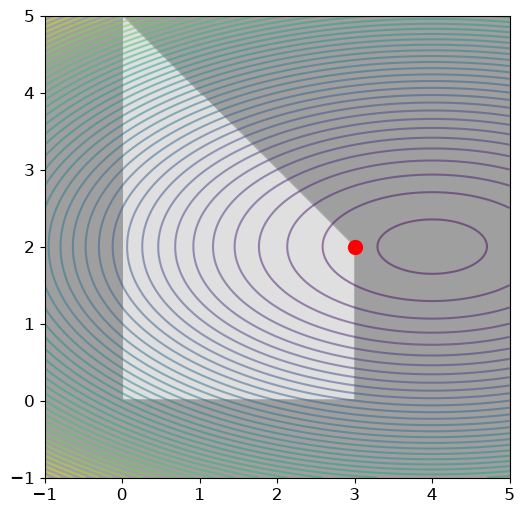

In [14]:
# Безусловный минимум (градиент=0): x1=4, x2=2. Проверка x1+x2 <= 5: 4+2 = 6 > 5. Минимум вне области!
P = matrix(np.array([[2.0, 0.0], [0.0, 8.0]]), tc='d')
q = matrix(np.array([-8.0, -16.0]), tc='d')
# Ограничения: x1 + x2 <= 5; -x1 <= 0; x1 <= 3; -x2 <= 0
G_qp = matrix(np.array([[ 1.0,  1.0], [-1.0,  0.0], [ 1.0,  0.0], [ 0.0, -1.0]]), tc='d')
h_qp = matrix(np.array([5.0, 0.0, 3.0, 0.0]), tc='d')

sol_qp = solvers.qp(P, q, G_qp, h_qp)
x_opt = np.array(sol_qp['x']).ravel()
print('Оптимальное решение QP с ограничениями:', x_opt)

# Визуализация
xx1, xx2 = np.meshgrid(np.linspace(-1, 5, 200), np.linspace(-1, 5, 200))
f = -8*xx1 - 16*xx2 + xx1**2 + 4*xx2**2
ok = (xx1 + xx2 <= 5) & (xx1 >= 0) & (xx1 <= 3) & (xx2 >= 0)
plt.figure(figsize=(6, 6))
plt.contour(xx1, xx2, f, 50, alpha=0.5)
plt.contourf(xx1, xx2, ok, 1, alpha=0.5, cmap='gray')
plt.scatter([x_opt[0]], [x_opt[1]], color='red', zorder=3, s=100)
plt.show()

5. Какие из ограничений **активны**, а какие можно выбросить без изменения решения? Проверьте экспериментально: решите задачу, удалив «лишнее» ограничение, и сравните ответы.

In [15]:
# Проверяем зазоры
for i, (g, h_i) in enumerate(zip(np.array(G_qp), np.array(h_qp).ravel())):
    slack = h_i - g @ x_opt
    print(f"Ограничение {i}: зазор = {slack:.4f} -> {'АКТИВНО' if abs(slack) < 1e-6 else 'неактивно'}")

# Активны x1+x2<=5 и x2>=0. Ограничение x1<=3 неактивно.
# Удаляем неактивное ограничение (3-ю строку) и проверяем:
G_rem = matrix(np.array([[ 1.0,  1.0], [-1.0,  0.0], [ 0.0, -1.0]]), tc='d')
h_rem = matrix(np.array([5.0, 0.0, 0.0]), tc='d')
sol_rem = solvers.qp(P, q, G_rem, h_rem)
print('Решение без неактивного ограничения:', np.array(sol_rem['x']).ravel())
# Ответ не изменится (1.67, 3.33).

Ограничение 0: зазор = 0.0013 -> неактивно
Ограничение 1: зазор = 3.0000 -> неактивно
Ограничение 2: зазор = 0.0000 -> АКТИВНО
Ограничение 3: зазор = 1.9987 -> неактивно
     pcost       dcost       gap    pres   dres
 0: -3.0419e+01 -3.8120e+01  8e+00  0e+00  2e-16
 1: -3.1027e+01 -3.1339e+01  3e-01  2e-16  4e-17
 2: -3.1196e+01 -3.1201e+01  6e-03  2e-16  2e-17
 3: -3.1200e+01 -3.1200e+01  6e-05  4e-16  2e-17
 4: -3.1200e+01 -3.1200e+01  6e-07  4e-17  4e-17
Optimal solution found.
Решение без неактивного ограничения: [3.19999978 1.79999995]


6. Сравните части A и B: в какой задаче оптимум обязан лежать на границе, а в какой может оказаться внутри области? Как это связано с видом целевой функции («плоскость» против «чаши»)?

## <h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 2. Линейный SVM</h2>

1. Сведите задачу обучения линейного SVM к QP (п. 2.4) и реализуйте обучение в классе `LinearSVM` (скелет ниже) при помощи QP-солвера. **Не забудьте:** солверу нужны метки $y_n \in \{+1, -1\}$; если метки закодированы нулями и единицами, преобразуйте их: `y = 2 * y - 1`.
2. Сгенерируйте три случайные двумерные выборки для бинарной классификации:
   - с линейно разделимыми классами;
   - с хорошо разделимыми классами, но **не линейно**;
   - с плохо разделимыми классами по имеющимся признакам.
3. Протестируйте линейный SVM на этих выборках. Покажите на плоскости разделяющую прямую и границы коридора $f(\boldsymbol x) = \pm 1$. Выделите опорные векторы точками другой формы или большего размера. Постройте классификаторы с разными значениями параметра $C$.
4. Как зависит число опорных векторов от параметра $C$ для каждой из выборок? Объясните, почему.
5. Используя явное преобразование признаков (п. 2.5), обучите методом опорных векторов квадратичную разделяющую поверхность и покажите её на плоскости.

## <h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 3. Двойственный SVM и ядра</h2>

1. Реализуйте процедуру обучения ядрового SVM (`DualSVM`) при помощи QP-солвера.
2. Протестируйте ядровой SVM на случайных двумерных выборках (удобно взять те же три, что и в задании 2). Покажите на плоскости разделяющие поверхности, границы коридора $f(\boldsymbol x) = \pm 1$ и опорные векторы. Попробуйте ядра:
   - линейное: $k(x, x') = x^T x'$;
   - полиномиальное: $k(x, x') = (x^T x' + 1)^p$ с различными степенями $p = 2, 3, \dots$;
   - гауссовское RBF: $k(x, x') = \exp(-\gamma \lVert x - x'\rVert^2)$.
3. Как ведёт себя SVM с полиномиальным ядром при увеличении $C$ и степени ядра $p$?
4. Как ведёт себя SVM с RBF-ядром при вариации $C$ и $\gamma$ (поварьируйте параметры по логарифмической сетке)? Какие значения параметров приводят к переобучению, а какие — к слишком грубой модели? На выборке «полумесяцы» сравните линейное, полиномиальное и RBF-ядра.

## <h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 4. SVM на реальных данных</h2>

1. Выполните загрузку, разведку и подготовку данных по чек-листу п. 4.2. В отчёте покажите таблицу до и после подготовки и поясните каждый шаг.
2. Обучите **свой** `LinearSVM` (из задания 2) на подготовленных данных. Подберите $C$ по логарифмической сетке $10^{-3}, \dots, 10^{5}$: посчитайте accuracy на train и test для каждого значения и изобразите оба графика в зависимости от $\log_{10} C$. Выберите лучшее $C$ и объясните выбор.
3. Обучите **свой** `DualSVM` с RBF-ядром: подберите пару $(C, \gamma)$ по логарифмической сетке (удобно построить тепловую карту качества). Стало ли лучше, чем с линейным SVM? На какой модели и параметрах остановитесь?
4. Проверьте себя: обучите [`sklearn.svm.SVC`](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) с `kernel='linear'` и `kernel='rbf'` на тех же данных и гиперпараметрах — качество должно получиться близким к вашему. Если различие велико — ищите ошибку в реализации.
5. Ответьте на вопросы в отчёте:
   - что произойдёт с качеством вашего SVM, если **не** масштабировать признаки? Проверьте экспериментально и объясните результат;
   - какие признаки сильнее всего влияют на диагноз? Для линейной SVM естественная мера важности признака $j$ — модуль веса $\lvert w_j \rvert$: отсортируйте признаки по важности и дайте клиническую интерпретацию — согласуется ли результат с медицинской интуицией (что важнее: боль в груди, возраст или холестерин?);
   - какую долю обучающей выборки составляют опорные векторы и как эта доля зависит от $C$? Много ли пациентов оказываются «на границе» диагноза?